In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("Salary Data.csv")
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
370,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
371,43.0,Male,Master's,Director of Operations,19.0,170000.0
372,29.0,Female,Bachelor's,Junior Project Manager,2.0,40000.0
373,34.0,Male,Bachelor's,Senior Operations Coordinator,7.0,90000.0


## Basic Checks

In [3]:
df.shape


(375, 6)

In [4]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [5]:
df.tail()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
370,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
371,43.0,Male,Master's,Director of Operations,19.0,170000.0
372,29.0,Female,Bachelor's,Junior Project Manager,2.0,40000.0
373,34.0,Male,Bachelor's,Senior Operations Coordinator,7.0,90000.0
374,44.0,Female,PhD,Senior Business Analyst,15.0,150000.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [7]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [8]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [9]:
df.duplicated().sum()

50

In [10]:
df1=df.drop_duplicates()

In [11]:
df1

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
348,28.0,Female,Bachelor's,Junior Operations Manager,1.0,35000.0
349,36.0,Male,Bachelor's,Senior Business Development Manager,8.0,110000.0
350,44.0,Female,PhD,Senior Data Scientist,16.0,160000.0
351,31.0,Male,Bachelor's,Junior Marketing Coordinator,3.0,55000.0


In [12]:
df1[df1.duplicated()]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary


## EDA

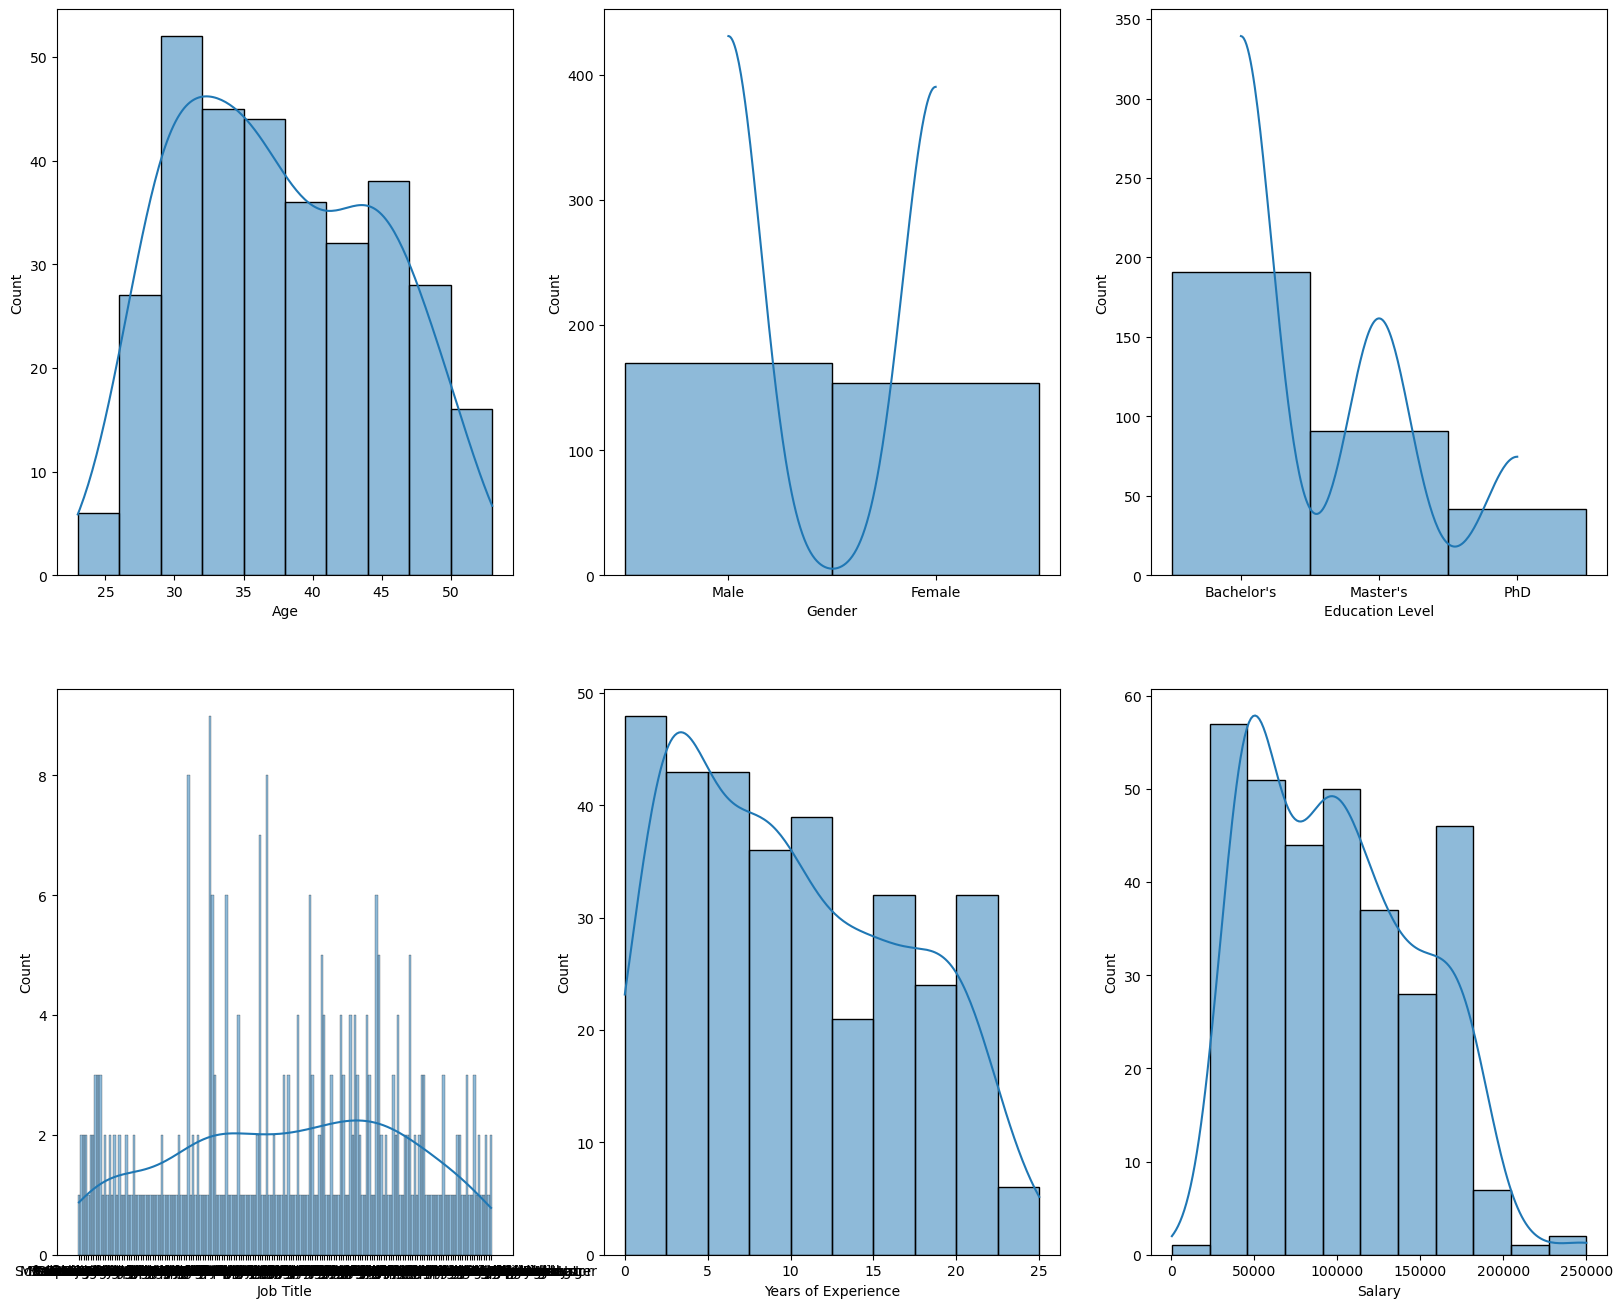

In [14]:
plt.figure(figsize=(20,25))
pos=1
for i in df1.columns:
    plt.subplot(3,3,pos)
    sns.histplot(df1[i],kde=True)
    pos=pos+1

## Data preprocessing and feature engineering

In [15]:
col=df1.columns
col

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [16]:
for col_name in col:
    if df1[col_name].dtypes=='object':
        df1[col_name]=df1[col_name].fillna(df1[col_name].mode()[0])
    else:
        df1[col_name]=df1[col_name].fillna(df1[col_name].median())


In [17]:
df1.isnull().sum()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [21]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for i in df1.columns:
    df1[i]=le.fit_transform(df1[i])
df1

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,9,1,0,159,7,13
1,5,0,1,17,5,8
2,23,1,2,130,17,25
3,13,0,0,101,9,7
4,30,1,1,22,22,33
...,...,...,...,...,...,...
348,5,0,0,68,2,2
349,13,1,0,111,10,17
350,22,0,2,115,18,27
351,8,1,0,63,5,6


In [22]:
res1=df1.corr(numeric_only=True)
res1

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
Age,1.000000,-0.032033,0.541678,0.125695,0.980272,0.922087
Gender,-0.032033,1.000000,-0.026629,0.035267,-0.001786,0.068575
Education Level,0.541678,-0.026629,1.000000,0.116060,0.571661,0.670842
Job Title,0.125695,0.035267,0.116060,1.000000,0.110310,0.165902
Years of Experience,0.980272,-0.001786,0.571661,0.110310,1.000000,0.928454
Salary,0.922087,0.068575,0.670842,0.165902,0.928454,1.000000


In [34]:
res=df1[df1.columns[:-1]].corr()
res

,Age,Gender,Education Level,Job Title,Years of Experience
Age,1.000000,-0.032033,0.541678,0.125695,0.980272
Gender,-0.032033,1.000000,-0.026629,0.035267,-0.001786
Education Level,0.541678,-0.026629,1.000000,0.116060,0.571661
Job Title,0.125695,0.035267,0.116060,1.000000,0.110310
Years of Experience,0.980272,-0.001786,0.571661,0.110310,1.000000


In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [57]:
x=df1.iloc[:,:-1]
y=df1.iloc[:,-1]

x_train,x_test,y_train,y_test=train_test_split(X_selected,y,train_size=0.75,random_state=42)

Selected Features: Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience'], dtype='object')


In [58]:
x


,Age,Gender,Education Level,Job Title,Years of Experience
0,9,1,0,159,7
1,5,0,1,17,5
2,23,1,2,130,17
3,13,0,0,101,9
4,30,1,1,22,22
...,...,...,...,...,...
348,5,0,0,68,2
349,13,1,0,111,10
350,22,0,2,115,18
351,8,1,0,63,5


In [59]:
y

0      13
1       8
2      25
3       7
4      33
       ..
348     2
349    17
350    27
351     6
371    28
Name: Salary, Length: 325, dtype: int64

In [60]:
l_model=LinearRegression()

In [62]:
l_model.fit(x_train,y_train)


LinearRegression()

In [63]:
y_pred=l_model.predict(x_test)

In [64]:
from sklearn.metrics import * 

In [65]:
r2_on_test=r2_score(y_test,y_pred)
r2_on_test

0.911472039265363